# 03c — Champion Evaluation & Selection

**Goal:** Evaluate the Optuna-tuned models from 03b on a held-out test set,
select the production champion through rigorous gate checks, and log it
to MLflow.

**Key design: no data leakage in threshold selection.**
We use a 3-way stratified split:
- **Train (70%)** — fit the pipeline
- **Validation (10%)** — tune the cost-optimal threshold
- **Test (20%)** — final unbiased evaluation (touched exactly once)

This prevents the threshold from being optimised on the same data used for
evaluation — a subtle but critical form of data leakage.

**Champion selection criteria (in priority order):**
1. **CV PR-AUC** — threshold-independent, robust to imbalance
2. **Test PR-AUC** — held-out confirmation (anti-overfitting check)
3. **Recall ≥ 0.70** — performance gate from `model_config.yaml`
4. **Precision ≥ 0.45** — guards against degenerate high-recall solutions
5. **Estimated savings** — business value at cost-optimal threshold (tie-breaker)

**Pipeline position:**
```
03a_algorithm_scan → 03b_hyperparameter_tuning → [THIS NOTEBOOK]
```

**Inputs:**
- `data/processed/tuning_results.pkl` (best params from 03b)
- `data/processed/phase1_scan_results.csv` (for scan-vs-tuned comparison)

**Outputs:**
- Champion model registered in MLflow Model Registry

## 0. Setup & Imports

In [1]:
import os
import sys
import warnings
import pickle
from pathlib import Path
from time import perf_counter

warnings.filterwarnings("ignore")

# ── Project root resolution ───────────────────────────────────────────────────
def find_project_root(marker: str = "pyproject.toml") -> Path:
    current = Path.cwd()
    for parent in [current, *current.parents]:
        if (parent / marker).exists():
            return parent
    raise FileNotFoundError(f"Could not locate project root from {current}")

PROJECT_ROOT = find_project_root()
os.chdir(PROJECT_ROOT)
sys.path.insert(0, str(PROJECT_ROOT))
print(f"Project root : {PROJECT_ROOT}")

# ── Third-party ───────────────────────────────────────────────────────────────
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import numpy as np
import pandas as pd
import seaborn as sns

from sklearn.calibration import CalibratedClassifierCV
from sklearn.ensemble import (
    ExtraTreesClassifier,
    GradientBoostingClassifier,
    RandomForestClassifier,
)
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    PrecisionRecallDisplay,
    RocCurveDisplay,
    confusion_matrix,
    ConfusionMatrixDisplay,
)
from sklearn.model_selection import train_test_split
from sklearn.svm import SVC
from catboost import CatBoostClassifier
from lightgbm import LGBMClassifier
from xgboost import XGBClassifier

import mlflow
import mlflow.sklearn
from mlflow.models import infer_signature
from dotenv import load_dotenv

# ── Project modules ────────────────────────────────────────────────────────────
from src.data.ingest import load_for_training
from src.data.validate import validate_raw_data
from src.data.preprocess import run_preprocessing
from src.models.pipeline import build_baseline_pipeline
from src.models.evaluate import evaluate, print_evaluation_report
from src.models.threshold import find_cost_optimal_threshold, find_f1_optimal_threshold
from src.utils.logging import get_logger
from src.utils.config_loader import get_config

logger = get_logger(__name__)
cfg    = get_config()

# ── Global constants ──────────────────────────────────────────────────────────
RANDOM_STATE = cfg.training.random_state
TEST_SIZE    = cfg.training.test_size
VAL_SIZE     = cfg.training.val_size
FN_COST      = cfg.model.cost_matrix.false_negative_cost  # $500
FP_COST      = cfg.model.cost_matrix.false_positive_cost  # $20

# Champion selection guard — minimum precision to avoid degenerate solutions.
MIN_PRECISION_GUARD = 0.45

# ── Plotting ──────────────────────────────────────────────────────────────────
sns.set_theme(style="whitegrid", palette="muted", font_scale=1.05)
plt.rcParams.update({"figure.dpi": 120})

print(f"Config → random_state={RANDOM_STATE}, test_size={TEST_SIZE}, val_size={VAL_SIZE}")
print(f"Gates  → min_roc_auc={cfg.model.performance_gates.min_roc_auc}, "
      f"min_pr_auc={cfg.model.performance_gates.min_pr_auc}, "
      f"min_recall={cfg.model.performance_gates.min_recall_at_threshold}")
print(f"Costs  → FN=${FN_COST:.0f}, FP=${FP_COST:.0f}")

Project root : /home/deepak/customer-churn-mlops


Config → random_state=42, test_size=0.2, val_size=0.1
Gates  → min_roc_auc=0.82, min_pr_auc=0.65, min_recall=0.7
Costs  → FN=$500, FP=$20


## 1. Load Data & Tuning Results

In [2]:
# Load and prepare data identically to 03a/03b
raw_df    = load_for_training()
validated = validate_raw_data(raw_df)
X, y      = run_preprocessing(validated)

# ── 3-way stratified split: train (70%) / val (10%) / test (20%) ──────────────
# First split: train+val (80%) vs test (20%)
X_trainval, X_test, y_trainval, y_test = train_test_split(
    X, y, test_size=TEST_SIZE, random_state=RANDOM_STATE, stratify=y
)

# Second split: train (70% of total) vs val (10% of total)
relative_val_size = VAL_SIZE / (1.0 - TEST_SIZE)
X_train, X_val, y_train, y_val = train_test_split(
    X_trainval, y_trainval,
    test_size=relative_val_size,
    random_state=RANDOM_STATE,
    stratify=y_trainval,
)

print(f"Train : {X_train.shape[0]} rows  |  churn {y_train.mean()*100:.1f}%")
print(f"Val   : {X_val.shape[0]} rows   |  churn {y_val.mean()*100:.1f}%  (threshold tuning only)")
print(f"Test  : {X_test.shape[0]} rows   |  churn {y_test.mean()*100:.1f}%  (final evaluation)")

2026-10-10 10:43:47 | INFO     | src.data.ingest | Loading training data from default path.


2026-10-10 10:43:47 | INFO     | src.data.ingest | Loading raw data from: /home/deepak/customer-churn-mlops/data/raw/WA_Fn-UseC_-Telco-Customer-Churn.csv


2026-10-10 10:43:47 | INFO     | src.data.ingest | Loaded raw data — shape: (7043, 21), columns: 21, memory: 7.8 MB


2026-10-10 10:43:47 | INFO     | src.data.validate | Starting raw data validation on DataFrame with shape (7043, 21).


2026-10-10 10:43:47 | INFO     | src.data.validate | fix_total_charges: found 11 blank TotalCharges rows (dtype was object). Imputing with MonthlyCharges.


...

2026-10-10 10:43:47 | INFO     | src.data.preprocess | Encoded target 'Churn': 1869 positives (churn=1), 5174 negatives (churn=0).


2026-10-10 10:43:47 | INFO     | src.data.preprocess | Dropped columns: ['customerID']


2026-10-10 10:43:47 | INFO     | src.data.preprocess | Preprocessing complete. Output shape: (7043, 20).


2026-10-10 10:43:47 | INFO     | src.data.preprocess | Split complete — X shape: (7043, 19), y shape: (7043,), positive rate: 26.54%.


Train : 4929 rows  |  churn 26.5%
Val   : 705 rows   |  churn 26.5%  (threshold tuning only)
Test  : 1409 rows   |  churn 26.5%  (final evaluation)


In [3]:
# Load tuning results from 03b
tuning_pkl_path = Path("data/processed/tuning_results.pkl")
if not tuning_pkl_path.exists():
    raise FileNotFoundError(
        f"Tuning results not found at {tuning_pkl_path}. "
        "Run 03b_hyperparameter_tuning.py first."
    )

with open(tuning_pkl_path, "rb") as f:
    tuning_results = pickle.load(f)

print(f"\nLoaded tuning results for {len(tuning_results)} models:")
for name, res in tuning_results.items():
    print(f"  {name:<26}  CV PR-AUC = {res['best_cv_pr_auc']:.4f}")

# Load Phase 1 results for comparison
phase1_df = pd.read_csv("data/processed/phase1_scan_results.csv")


Loaded tuning results for 5 models:
  Logistic Regression         CV PR-AUC = 0.6686
  Random Forest               CV PR-AUC = 0.6652
  Gradient Boosting           CV PR-AUC = 0.6712
  Extra Trees                 CV PR-AUC = 0.6612
  CatBoost                    CV PR-AUC = 0.6692


## 2. Reconstruct & Fit Tuned Pipelines

Rebuild each tuned model from its Optuna best params, then fit on the
**training set**. The validation set is used exclusively for threshold
tuning. The test set remains untouched until Section 3.

In [4]:
def build_tuned_estimator(name: str, params: dict):
    """Reconstruct an unfitted estimator from Optuna best params."""
    p = params.copy()

    if name == "LightGBM":
        return LGBMClassifier(**p, random_state=RANDOM_STATE, verbose=-1, n_jobs=-1)

    elif name == "XGBoost":
        p.update({"eval_metric": "logloss", "verbosity": 0,
                  "random_state": RANDOM_STATE, "n_jobs": -1})
        return XGBClassifier(**p)

    elif name == "CatBoost":
        p.update({"auto_class_weights": "Balanced",
                  "random_seed": RANDOM_STATE, "verbose": 0})
        return CatBoostClassifier(**p)

    elif name == "Random Forest":
        p.update({"class_weight": "balanced_subsample",
                  "random_state": RANDOM_STATE, "n_jobs": -1})
        return RandomForestClassifier(**p)

    elif name == "Extra Trees":
        p.update({"class_weight": "balanced_subsample",
                  "random_state": RANDOM_STATE, "n_jobs": -1})
        return ExtraTreesClassifier(**p)

    elif name == "Gradient Boosting":
        p.update({"random_state": RANDOM_STATE})
        return GradientBoostingClassifier(**p)

    elif name == "Logistic Regression":
        p.update({"solver": "saga", "max_iter": 3000,
                  "class_weight": "balanced", "random_state": RANDOM_STATE})
        return LogisticRegression(**p)

    elif name == "SVC (calibrated)":
        kernel = p.pop("kernel")
        degree = p.pop("degree", 3)
        gamma  = p.pop("gamma")
        C      = p.pop("C")
        svc_params = dict(kernel=kernel, C=C, gamma=gamma,
                          class_weight="balanced", random_state=RANDOM_STATE)
        if kernel == "poly":
            svc_params["degree"] = degree
        return CalibratedClassifierCV(SVC(**svc_params), method="isotonic", cv=3)

    else:
        raise ValueError(f"Unknown model name: {name}")

In [5]:
fitted_tuned: dict[str, object] = {}
final_results: dict[str, dict] = {}

tuning_candidates = list(tuning_results.keys())

print("Fitting tuned models on training set...\n")

for name in tuning_candidates:
    best_params = tuning_results[name]["best_params"]
    estimator   = build_tuned_estimator(name, best_params)
    pipeline    = build_baseline_pipeline(estimator)

    t0 = perf_counter()
    pipeline.fit(X_train, y_train)
    fitted_tuned[name] = pipeline
    elapsed = perf_counter() - t0

    # Find threshold on VALIDATION set (not test — no data leakage)
    y_val_proba   = pipeline.predict_proba(X_val)[:, 1]
    thresh_cost   = find_cost_optimal_threshold(y_val.values, y_val_proba)
    thresh_f1     = find_f1_optimal_threshold(y_val.values, y_val_proba)

    # Evaluate on held-out TEST set with threshold from validation
    y_test_proba  = pipeline.predict_proba(X_test)[:, 1]
    test_metrics  = evaluate(y_test.values, y_test_proba, thresh_cost)

    final_results[name] = {
        **test_metrics,
        "tuned_cv_pr_auc"  : tuning_results[name]["best_cv_pr_auc"],
        "optimal_threshold": thresh_cost,
        "f1_threshold"     : thresh_f1,
        "fit_time_s"       : round(elapsed, 1),
    }

    print(
        f"  {name:<26} | "
        f"Test PR-AUC {test_metrics['pr_auc']:.4f} | "
        f"ROC-AUC {test_metrics['roc_auc']:.4f} | "
        f"Recall {test_metrics['recall']:.4f} | "
        f"Precision {test_metrics['precision']:.4f} | "
        f"thresh={thresh_cost:.2f} (from val set)"
    )

Fitting tuned models on training set...

2026-10-10 10:43:47 | INFO     | src.features.feature_store | Engineering features for DataFrame with shape (4929, 19).


2026-10-10 10:43:47 | INFO     | src.features.feature_store | Feature engineering complete. Output shape (4929, 47). Added 28 new columns.


[LightGBM] [Info] Number of positive: 1308, number of negative: 3621
[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.000327 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 1525
[LightGBM] [Info] Number of data points in the train set: 4929, number of used features: 80
[LightGBM] [Info] [binary:BoostFromScore]: pavg=0.265368 -> initscore=-1.018251
[LightGBM] [Info] Start training from score -1.018251


2026-10-10 10:43:48 | INFO     | src.features.feature_store | Engineering features for DataFrame with shape (705, 19).


2026-10-10 10:43:48 | INFO     | src.features.feature_store | Feature engineering complete. Output shape (705, 47). Added 28 new columns.


...

2026-10-10 10:44:00 | INFO     | src.models.threshold | F1-optimal threshold: 0.63 (best F1: 0.6972)


2026-10-10 10:44:00 | INFO     | src.features.feature_store | Engineering features for DataFrame with shape (1409, 19).


2026-10-10 10:44:00 | INFO     | src.features.feature_store | Feature engineering complete. Output shape (1409, 47). Added 28 new columns.


2026-10-10 10:44:01 | INFO     | src.models.evaluate | Evaluation complete — ROC-AUC: 0.8446 | PR-AUC: 0.6534 | Recall: 0.9920 | Estimated savings: $170920


  CatBoost                   | Test PR-AUC 0.6534 | ROC-AUC 0.8446 | Recall 0.9920 | Precision 0.3373 | thresh=0.09 (from val set)


## 3. Results Analysis

In [6]:
final_df = (
    pd.DataFrame(final_results).T.reset_index().rename(columns={"index": "model"})
)
num_cols = [c for c in final_df.columns if c != "model"]
final_df[num_cols] = final_df[num_cols].apply(pd.to_numeric)
final_df = final_df.sort_values("pr_auc", ascending=False).reset_index(drop=True)
final_df.index += 1

# Performance gates check
gates = cfg.model.performance_gates

def gate_check(row) -> str:
    return "✅ PASS" if (
        row["roc_auc"]   >= gates.min_roc_auc              and
        row["pr_auc"]    >= gates.min_pr_auc                and
        row["recall"]    >= gates.min_recall_at_threshold   and
        row["precision"] >= MIN_PRECISION_GUARD            # degenerate solution guard
    ) else "❌ FAIL"

final_df["gates"] = final_df.apply(gate_check, axis=1)

display_cols = [
    "model", "tuned_cv_pr_auc", "pr_auc", "roc_auc", "f1",
    "precision", "recall", "optimal_threshold",
    "estimated_savings", "total_cost", "gates",
]

print("\n── Final Evaluation: Tuned Models on Test Set ──────────────────────")
print("    (thresholds tuned on validation set — test set untouched until now)")
print(final_df[display_cols].to_string(float_format="{:.4f}".format))


── Final Evaluation: Tuned Models on Test Set ──────────────────────
    (thresholds tuned on validation set — test set untouched until now)
                 model  tuned_cv_pr_auc  pr_auc  roc_auc     f1  precision  recall  optimal_threshold  estimated_savings  total_cost   gates
1  Logistic Regression           0.6686  0.6647   0.8449 0.5198     0.3536  0.9813             0.1300        170080.0000  16920.0000  ❌ FAIL
2    Gradient Boosting           0.6712  0.6610   0.8448 0.5103     0.3439  0.9893             0.0500        170880.0000  16120.0000  ❌ FAIL
3        Random Forest           0.6652  0.6577   0.8445 0.4616     0.3003  0.9973             0.0400        169120.0000  17880.0000  ❌ FAIL
4             CatBoost           0.6692  0.6534   0.8446 0.5034     0.3373  0.9920             0.0900        170920.0000  16080.0000  ❌ FAIL
5          Extra Trees           0.6612  0.6454   0.8388 0.5265     0.3612  0.9706             0.1600        168660.0000  18340.0000  ❌ FAIL


### 3.1 CV vs Test PR-AUC — Overfitting Check

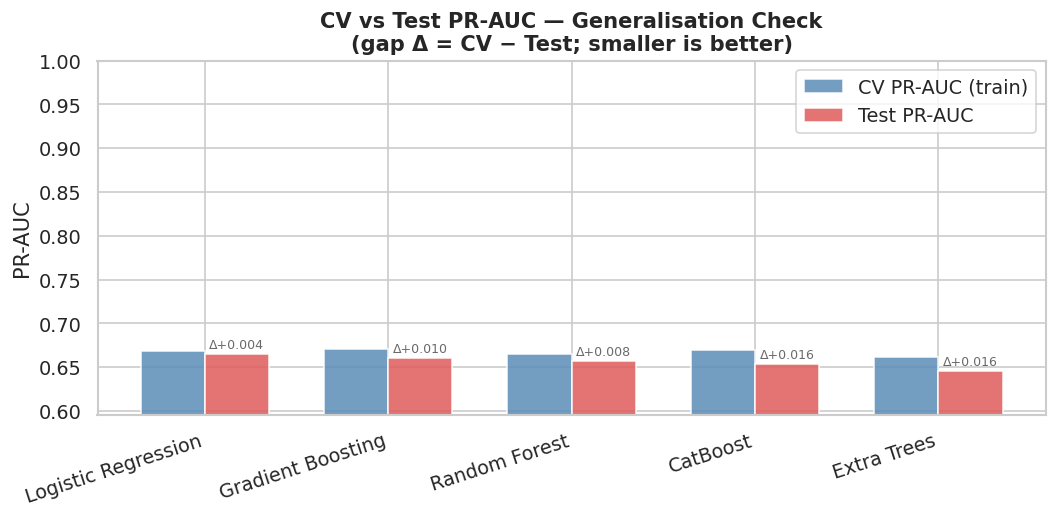

In [7]:
fig, ax = plt.subplots(figsize=(9, 4.5))
x = np.arange(len(final_df))
w = 0.35
ax.bar(x - w/2, final_df["tuned_cv_pr_auc"], width=w, label="CV PR-AUC (train)", alpha=0.85, color="#5b8db8")
ax.bar(x + w/2, final_df["pr_auc"],          width=w, label="Test PR-AUC",       alpha=0.85, color="#e05c5c")

for i, (cv_v, test_v) in enumerate(zip(final_df["tuned_cv_pr_auc"], final_df["pr_auc"])):
    gap = cv_v - test_v
    ax.text(x[i] + w/2, test_v + 0.003, f"Δ{gap:+.3f}", ha="center", va="bottom",
            fontsize=7.5, color="dimgray")

ax.set_xticks(x)
ax.set_xticklabels(final_df["model"], rotation=18, ha="right")
ax.set_ylabel("PR-AUC")
ax.set_ylim(max(0, final_df[["tuned_cv_pr_auc", "pr_auc"]].min().min() - 0.05), 1.0)
ax.legend()
ax.set_title("CV vs Test PR-AUC — Generalisation Check\n"
             "(gap Δ = CV − Test; smaller is better)", fontweight="bold")
plt.tight_layout()
plt.savefig("reports/cv_vs_test_pr_auc.png", dpi=150, bbox_inches="tight")
plt.show()

### 3.2 Precision–Recall Trade-off

This scatter plot exposes degenerate solutions:
a model in the **bottom-right** (high recall, low precision) is
essentially flagging everyone — not a genuine champion.

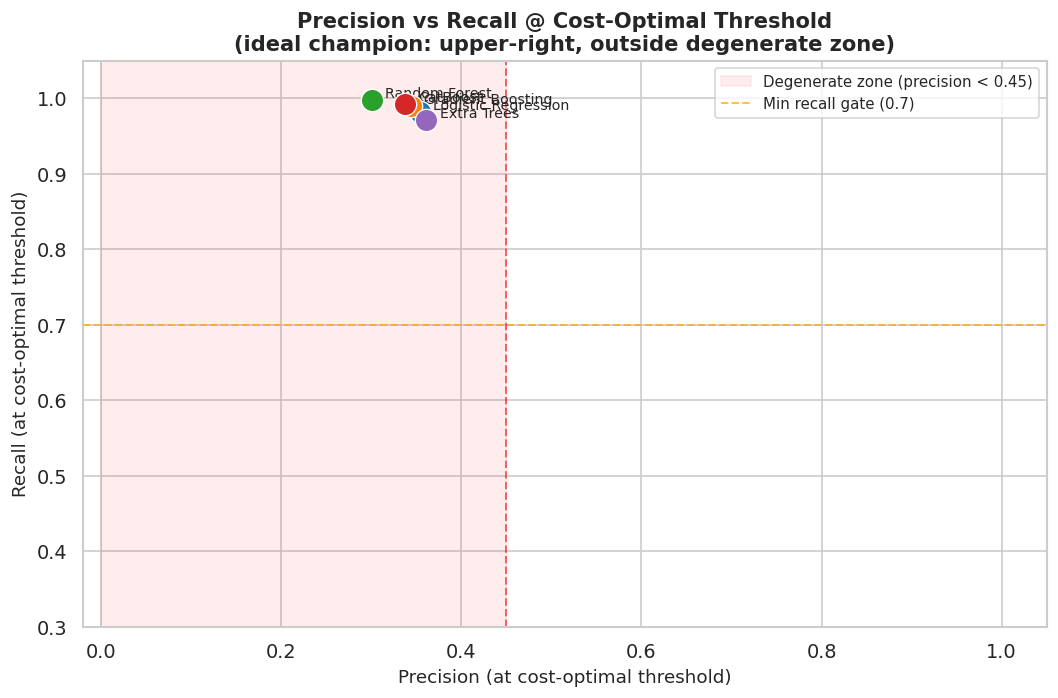

In [8]:
fig, ax = plt.subplots(figsize=(9, 6))
colors_scatter = sns.color_palette("tab10", n_colors=len(final_df))

for (_, row), color in zip(final_df.iterrows(), colors_scatter):
    ax.scatter(row["precision"], row["recall"], s=180, color=color,
               zorder=5, edgecolors="white", linewidths=0.8)
    ax.annotate(
        row["model"], (row["precision"], row["recall"]),
        textcoords="offset points", xytext=(8, 2), fontsize=8.5,
    )

# Degenerate solution zone
ax.axvspan(0.0, MIN_PRECISION_GUARD, alpha=0.07, color="red",
           label=f"Degenerate zone (precision < {MIN_PRECISION_GUARD})")
ax.axvline(MIN_PRECISION_GUARD, color="red", linestyle="--", lw=1.2, alpha=0.6)

ax.axhline(gates.min_recall_at_threshold, color="orange", linestyle="--", lw=1.2,
           alpha=0.7, label=f"Min recall gate ({gates.min_recall_at_threshold})")

ax.set_xlabel("Precision (at cost-optimal threshold)", fontsize=11)
ax.set_ylabel("Recall (at cost-optimal threshold)", fontsize=11)
ax.set_title("Precision vs Recall @ Cost-Optimal Threshold\n"
             "(ideal champion: upper-right, outside degenerate zone)", fontweight="bold")
ax.set_xlim(-0.02, 1.05)
ax.set_ylim(0.3, 1.05)
ax.legend(fontsize=9)
plt.tight_layout()
plt.savefig("reports/precision_recall_scatter.png", dpi=150, bbox_inches="tight")
plt.show()

### 3.3 PR Curves & ROC Curves

2026-10-10 10:44:01 | INFO     | src.features.feature_store | Engineering features for DataFrame with shape (1409, 19).


2026-10-10 10:44:01 | INFO     | src.features.feature_store | Feature engineering complete. Output shape (1409, 47). Added 28 new columns.


2026-10-10 10:44:01 | INFO     | src.features.feature_store | Engineering features for DataFrame with shape (1409, 19).


2026-10-10 10:44:01 | INFO     | src.features.feature_store | Feature engineering complete. Output shape (1409, 47). Added 28 new columns.


2026-10-10 10:44:02 | INFO     | src.features.feature_store | Engineering features for DataFrame with shape (1409, 19).


...

2026-10-10 10:44:02 | INFO     | src.features.feature_store | Feature engineering complete. Output shape (1409, 47). Added 28 new columns.


2026-10-10 10:44:02 | INFO     | src.features.feature_store | Engineering features for DataFrame with shape (1409, 19).


2026-10-10 10:44:02 | INFO     | src.features.feature_store | Feature engineering complete. Output shape (1409, 47). Added 28 new columns.


2026-10-10 10:44:03 | INFO     | src.features.feature_store | Engineering features for DataFrame with shape (1409, 19).


2026-10-10 10:44:03 | INFO     | src.features.feature_store | Feature engineering complete. Output shape (1409, 47). Added 28 new columns.


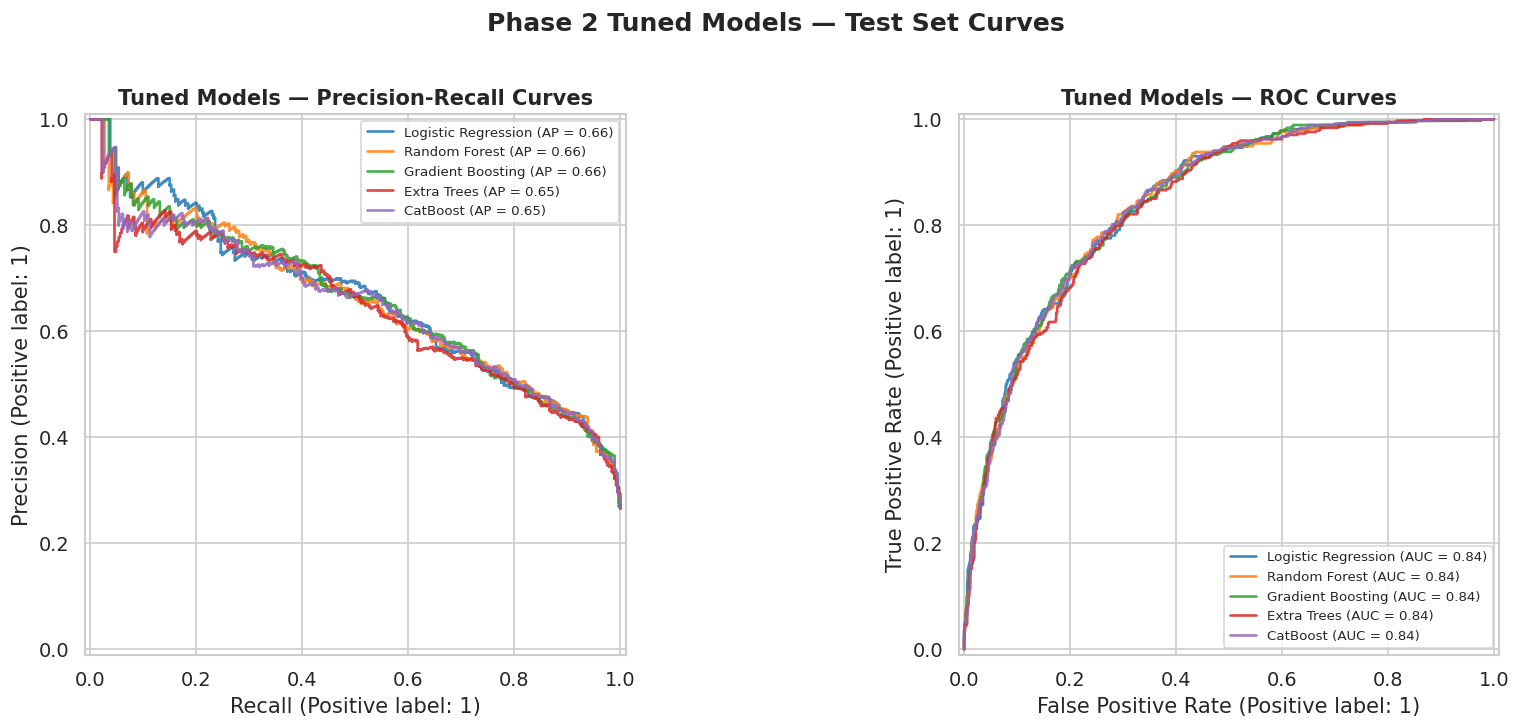

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(15, 6))
palette = sns.color_palette("tab10", n_colors=len(fitted_tuned))

for ax, curve_cls, title in [
    (axes[0], PrecisionRecallDisplay, "Precision-Recall Curves"),
    (axes[1], RocCurveDisplay,        "ROC Curves"),
]:
    for (name, pipeline), color in zip(fitted_tuned.items(), palette):
        y_proba = pipeline.predict_proba(X_test)[:, 1]
        curve_cls.from_predictions(
            y_test.values, y_proba, name=name, ax=ax,
            color=color, lw=1.6, alpha=0.85,
        )
    ax.set_title(f"Tuned Models — {title}", fontweight="bold")
    ax.legend(fontsize=8, loc="lower right" if "ROC" in title else "upper right")

plt.suptitle("Phase 2 Tuned Models — Test Set Curves", fontweight="bold", y=1.01)
plt.tight_layout()
plt.savefig("reports/tuned_models_curves.png", dpi=150, bbox_inches="tight")
plt.show()

### 3.4 Metrics Heatmap

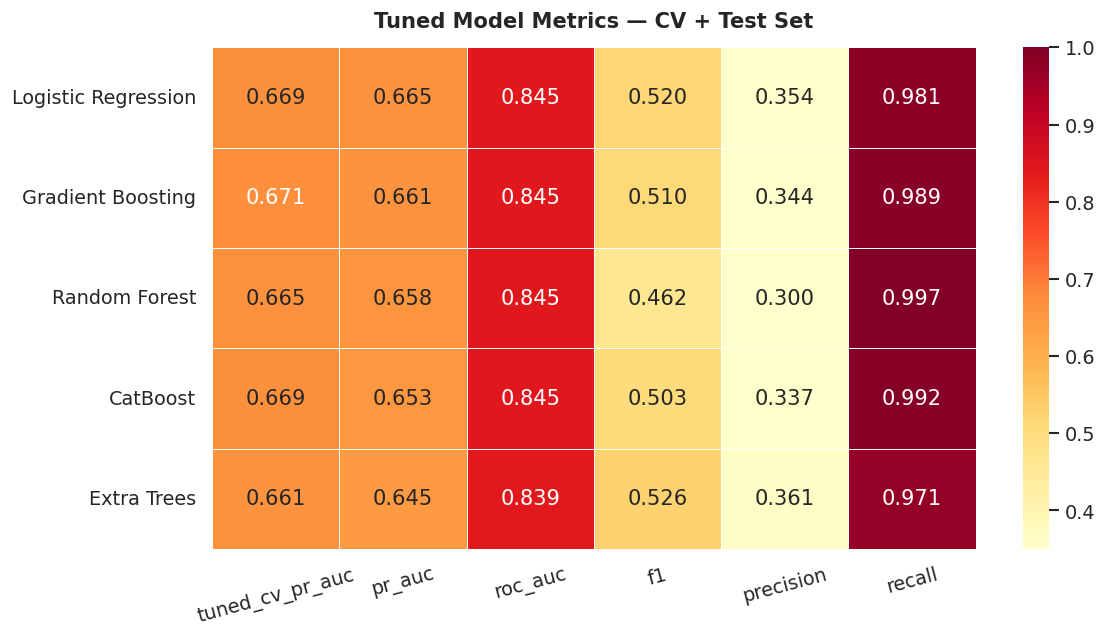

In [10]:
heatmap_metrics = ["tuned_cv_pr_auc", "pr_auc", "roc_auc", "f1", "precision", "recall"]
heatmap_data    = final_df.set_index("model")[heatmap_metrics].astype(float)

fig, ax = plt.subplots(figsize=(10, 5.5))
sns.heatmap(
    heatmap_data, annot=True, fmt=".3f",
    cmap="YlOrRd", linewidths=0.5,
    vmin=0.35, vmax=1.0, ax=ax,
)
ax.set_title("Tuned Model Metrics — CV + Test Set", fontweight="bold", pad=12)
ax.set_xlabel("")
ax.set_ylabel("")
plt.xticks(rotation=15)
plt.yticks(rotation=0)
plt.tight_layout()
plt.savefig("reports/metrics_heatmap.png", dpi=150, bbox_inches="tight")
plt.show()

### 3.5 Business Impact (Tuned Models)

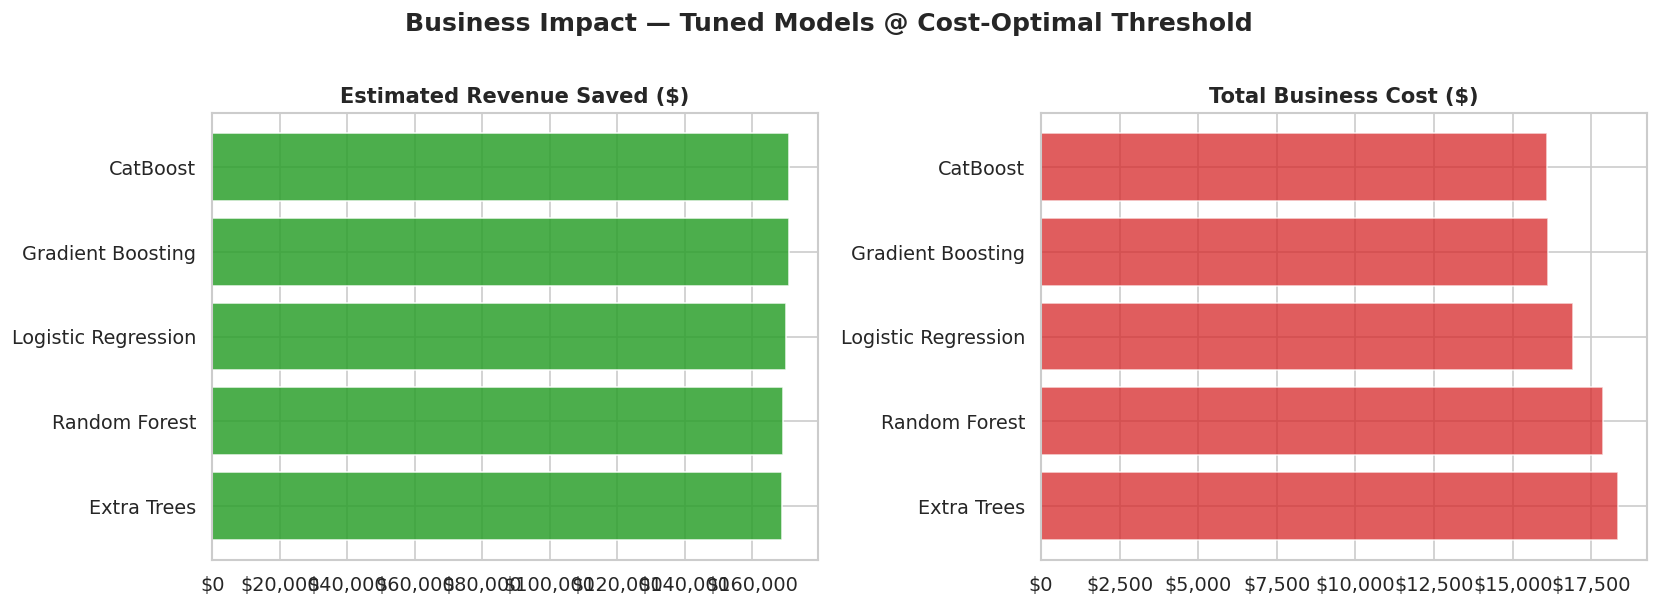

In [11]:
biz_df = (
    final_df[["model", "estimated_savings", "total_cost",
               "true_positives", "false_positives", "false_negatives"]]
    .sort_values("estimated_savings", ascending=False).reset_index(drop=True)
)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].barh(biz_df["model"][::-1], biz_df["estimated_savings"][::-1],
             color="#2ca02c", alpha=0.85)
axes[0].set_title("Estimated Revenue Saved ($)", fontweight="bold")
axes[0].xaxis.set_major_formatter(mticker.StrMethodFormatter("${x:,.0f}"))

axes[1].barh(biz_df["model"][::-1], biz_df["total_cost"][::-1],
             color="#d62728", alpha=0.75)
axes[1].set_title("Total Business Cost ($)", fontweight="bold")
axes[1].xaxis.set_major_formatter(mticker.StrMethodFormatter("${x:,.0f}"))

plt.suptitle("Business Impact — Tuned Models @ Cost-Optimal Threshold", fontweight="bold", y=1.01)
plt.tight_layout()
plt.savefig("reports/business_impact.png", dpi=150, bbox_inches="tight")
plt.show()

### 3.6 Threshold Sensitivity — Top-3 Tuned Models

2026-10-10 10:44:04 | INFO     | src.features.feature_store | Engineering features for DataFrame with shape (1409, 19).


2026-10-10 10:44:04 | INFO     | src.features.feature_store | Feature engineering complete. Output shape (1409, 47). Added 28 new columns.


2026-10-10 10:44:04 | INFO     | src.features.feature_store | Engineering features for DataFrame with shape (1409, 19).


2026-10-10 10:44:04 | INFO     | src.features.feature_store | Feature engineering complete. Output shape (1409, 47). Added 28 new columns.


2026-10-10 10:44:04 | INFO     | src.features.feature_store | Engineering features for DataFrame with shape (1409, 19).


2026-10-10 10:44:04 | INFO     | src.features.feature_store | Feature engineering complete. Output shape (1409, 47). Added 28 new columns.


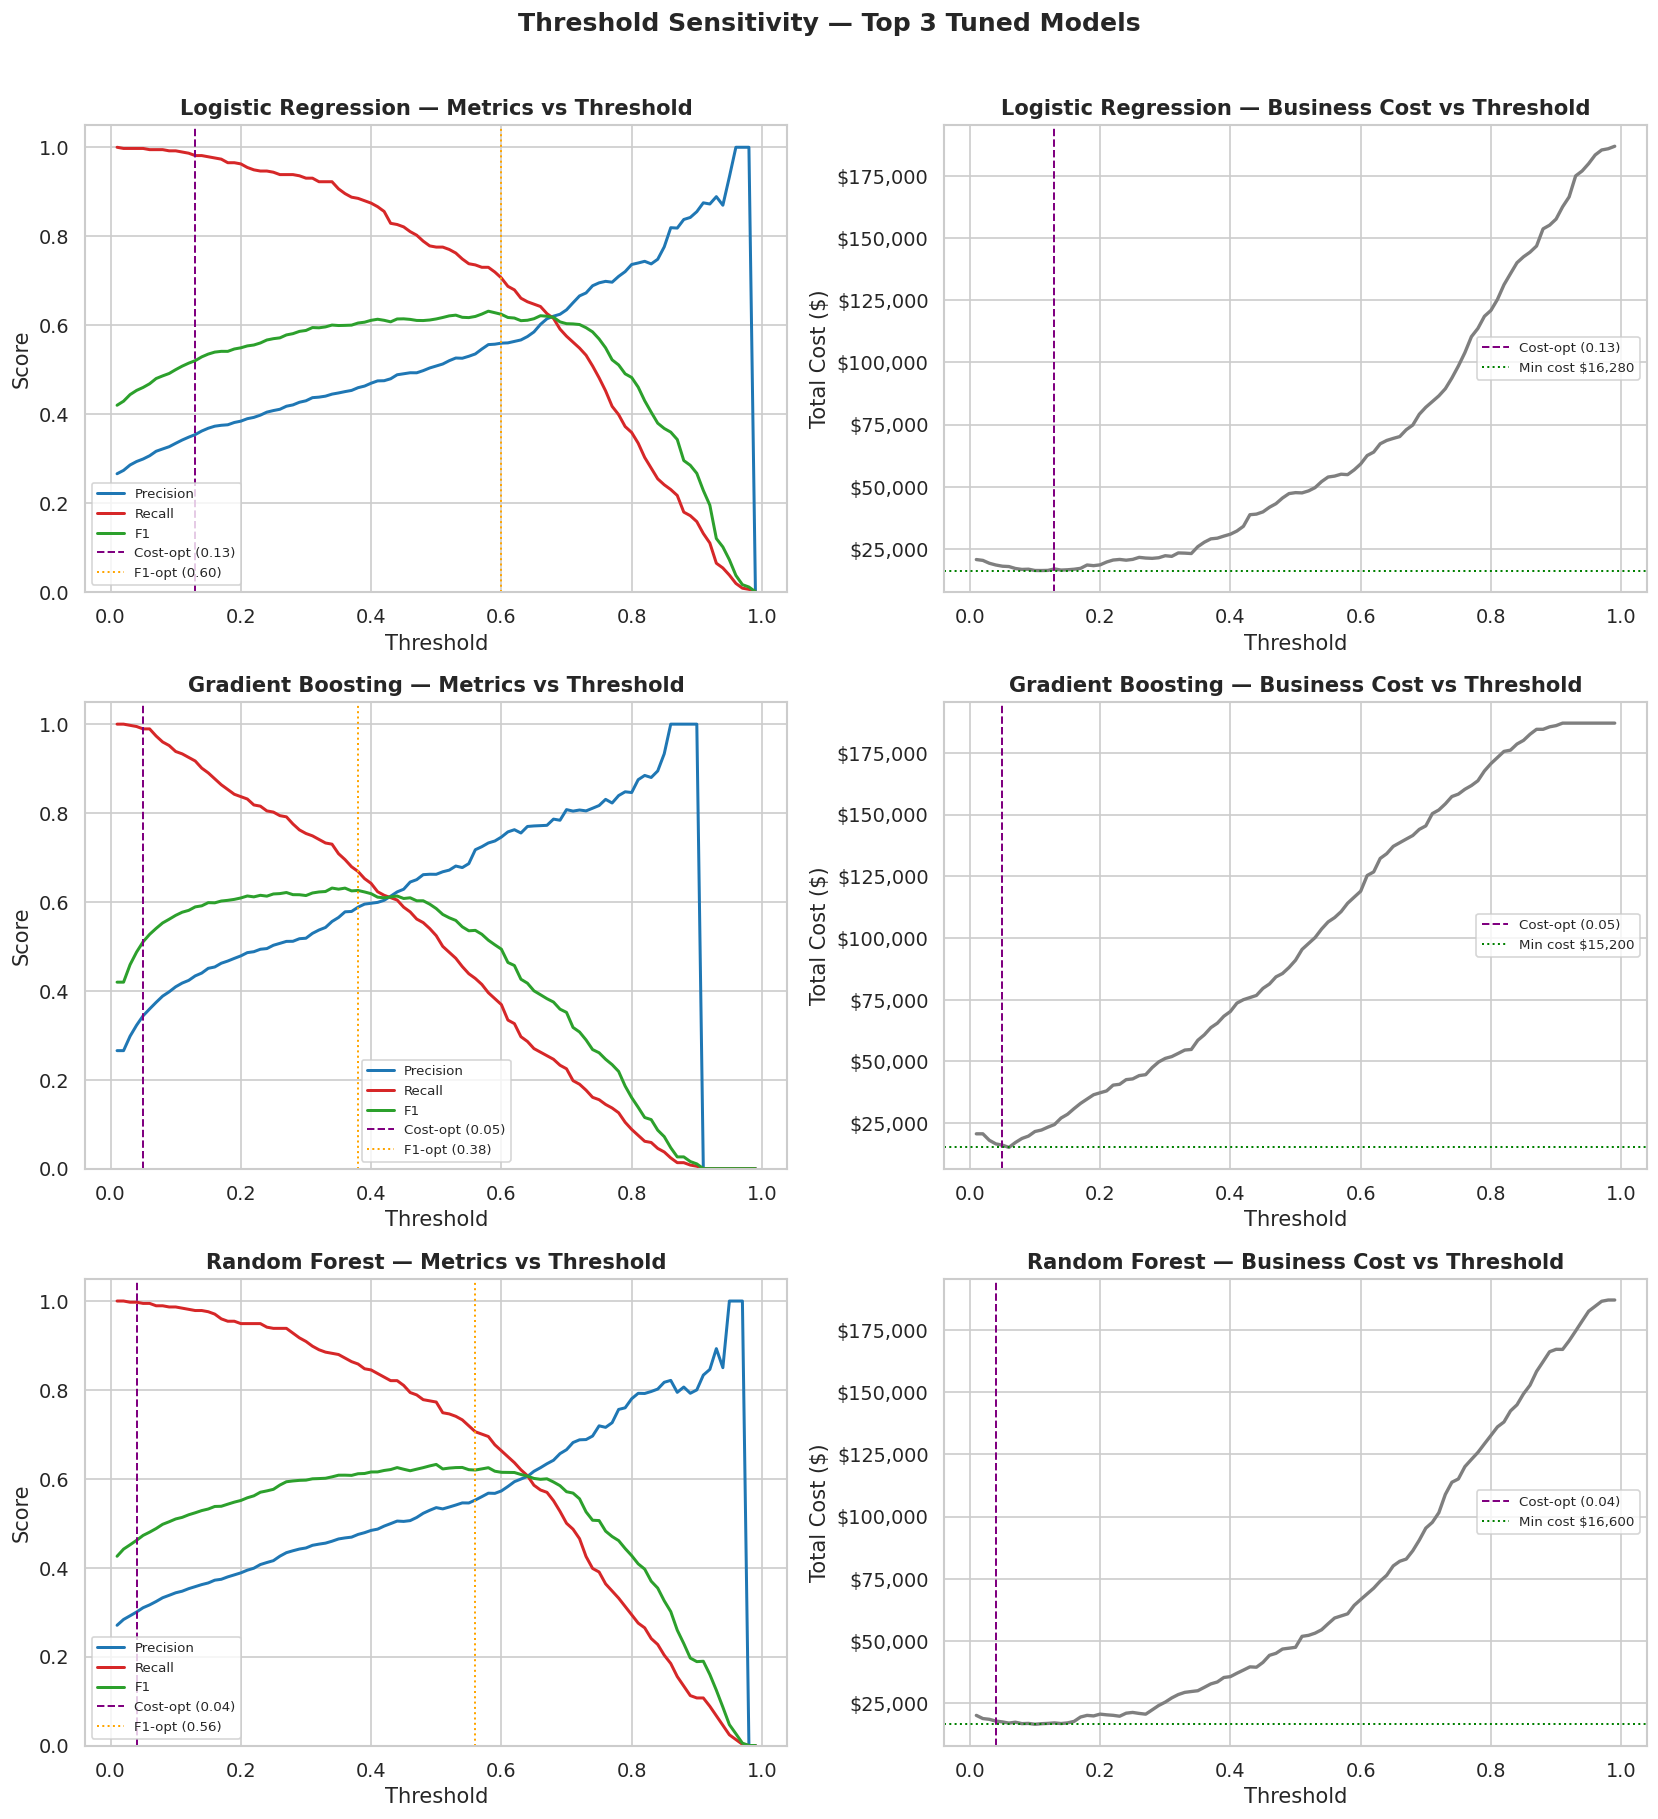

In [12]:
THRESHOLDS = np.linspace(0.01, 0.99, 99)

def threshold_sweep(y_true: np.ndarray, y_proba: np.ndarray) -> pd.DataFrame:
    rows = []
    for t in THRESHOLDS:
        y_pred = (y_proba >= t).astype(int)
        tp = ((y_pred == 1) & (y_true == 1)).sum()
        fp = ((y_pred == 1) & (y_true == 0)).sum()
        fn = ((y_pred == 0) & (y_true == 1)).sum()
        prec = tp / (tp + fp) if (tp + fp) > 0 else 0.0
        rec  = tp / (tp + fn) if (tp + fn) > 0 else 0.0
        f1   = 2 * prec * rec / (prec + rec) if (prec + rec) > 0 else 0.0
        cost = fn * FN_COST + fp * FP_COST
        rows.append({"threshold": t, "precision": prec, "recall": rec,
                     "f1": f1, "total_cost": cost})
    return pd.DataFrame(rows)


top3_final = final_df["model"].head(3).tolist()
fig, axes  = plt.subplots(len(top3_final), 2, figsize=(14, 5 * len(top3_final)))

for row_idx, name in enumerate(top3_final):
    y_proba  = fitted_tuned[name].predict_proba(X_test)[:, 1]
    sweep    = threshold_sweep(y_test.values, y_proba)
    opt_t    = final_results[name]["optimal_threshold"]
    f1_t     = final_results[name]["f1_threshold"]

    ax = axes[row_idx][0]
    ax.plot(sweep["threshold"], sweep["precision"], label="Precision", color="#1f77b4", lw=1.8)
    ax.plot(sweep["threshold"], sweep["recall"],    label="Recall",    color="#d62728", lw=1.8)
    ax.plot(sweep["threshold"], sweep["f1"],        label="F1",        color="#2ca02c", lw=1.8)
    ax.axvline(opt_t, color="purple", linestyle="--", lw=1.2, label=f"Cost-opt ({opt_t:.2f})")
    ax.axvline(f1_t,  color="orange", linestyle=":",  lw=1.2, label=f"F1-opt ({f1_t:.2f})")
    ax.set_title(f"{name} — Metrics vs Threshold", fontweight="bold")
    ax.set_xlabel("Threshold"); ax.set_ylabel("Score")
    ax.legend(fontsize=8); ax.set_ylim(0, 1.05)

    ax = axes[row_idx][1]
    ax.plot(sweep["threshold"], sweep["total_cost"], color="#7f7f7f", lw=2)
    ax.axvline(opt_t, color="purple", linestyle="--", lw=1.2, label=f"Cost-opt ({opt_t:.2f})")
    min_cost = sweep["total_cost"].min()
    ax.axhline(min_cost, color="green", linestyle=":", lw=1.2, label=f"Min cost ${min_cost:,.0f}")
    ax.set_title(f"{name} — Business Cost vs Threshold", fontweight="bold")
    ax.set_xlabel("Threshold"); ax.set_ylabel("Total Cost ($)")
    ax.yaxis.set_major_formatter(mticker.StrMethodFormatter("${x:,.0f}"))
    ax.legend(fontsize=8)

plt.suptitle("Threshold Sensitivity — Top 3 Tuned Models", fontweight="bold", y=1.01)
plt.tight_layout()
plt.savefig("reports/threshold_sensitivity.png", dpi=150, bbox_inches="tight")
plt.show()

### 3.7 Confusion Matrices — Top-3 Tuned Models

2026-10-10 10:44:06 | INFO     | src.features.feature_store | Engineering features for DataFrame with shape (1409, 19).


2026-10-10 10:44:06 | INFO     | src.features.feature_store | Feature engineering complete. Output shape (1409, 47). Added 28 new columns.


2026-10-10 10:44:06 | INFO     | src.features.feature_store | Engineering features for DataFrame with shape (1409, 19).


2026-10-10 10:44:06 | INFO     | src.features.feature_store | Feature engineering complete. Output shape (1409, 47). Added 28 new columns.


2026-10-10 10:44:06 | INFO     | src.features.feature_store | Engineering features for DataFrame with shape (1409, 19).


2026-10-10 10:44:06 | INFO     | src.features.feature_store | Feature engineering complete. Output shape (1409, 47). Added 28 new columns.


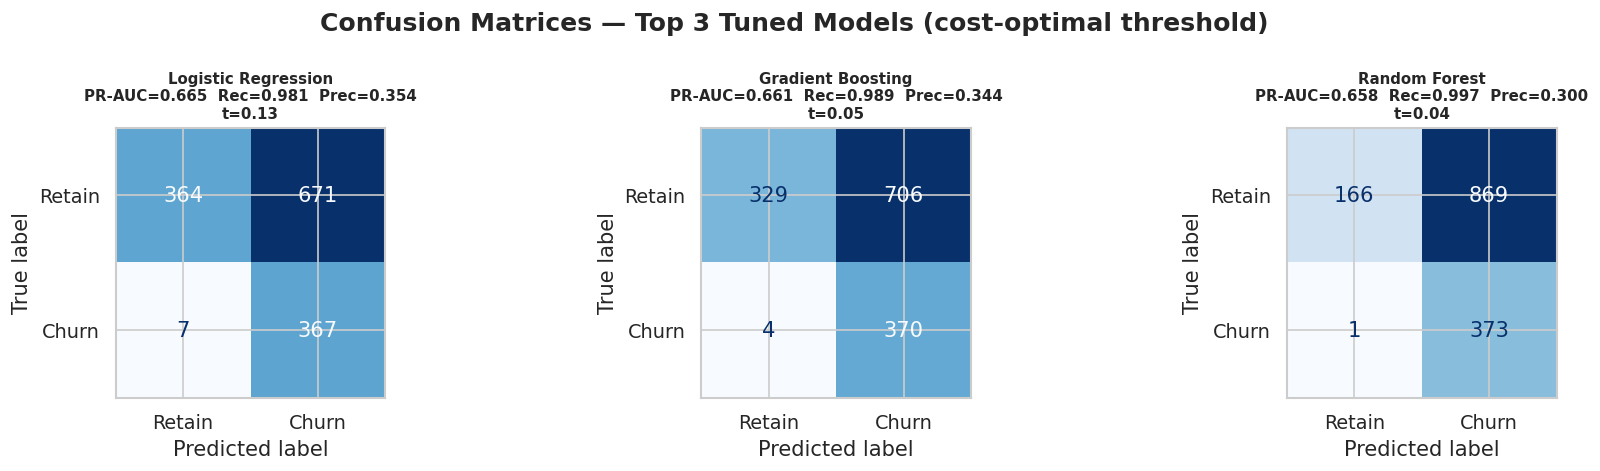

In [13]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

for ax, name in zip(axes, top3_final):
    y_proba = fitted_tuned[name].predict_proba(X_test)[:, 1]
    thresh  = final_results[name]["optimal_threshold"]
    y_pred  = (y_proba >= thresh).astype(int)
    cm      = confusion_matrix(y_test.values, y_pred)
    ConfusionMatrixDisplay(cm, display_labels=["Retain", "Churn"]).plot(
        ax=ax, colorbar=False, cmap="Blues"
    )
    pr  = final_results[name]["pr_auc"]
    rec = final_results[name]["recall"]
    prec= final_results[name]["precision"]
    ax.set_title(f"{name}\nPR-AUC={pr:.3f}  Rec={rec:.3f}  Prec={prec:.3f}\n"
                 f"t={thresh:.2f}", fontsize=9, fontweight="bold")

plt.suptitle("Confusion Matrices — Top 3 Tuned Models (cost-optimal threshold)", fontweight="bold")
plt.tight_layout()
plt.savefig("reports/confusion_matrices.png", dpi=150, bbox_inches="tight")
plt.show()

### 3.8 Feature Importance — Champion Candidates

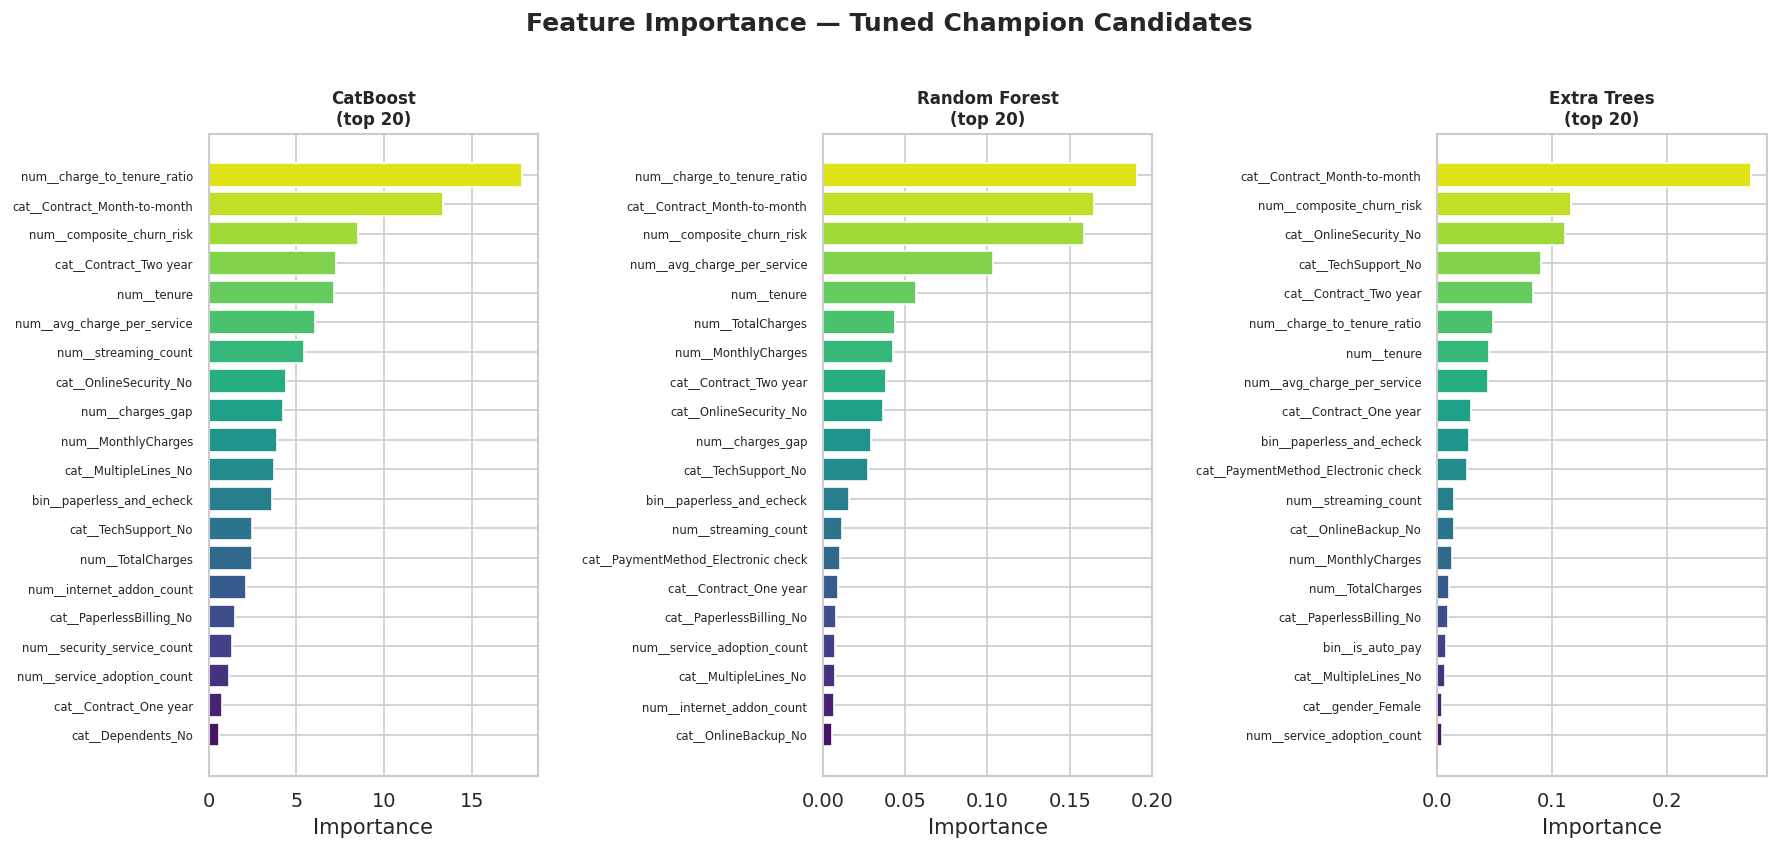

In [14]:
TREE_IMPORTANCE_MODELS = ["LightGBM", "XGBoost", "CatBoost", "Random Forest", "Extra Trees"]
available_tree_models  = [n for n in TREE_IMPORTANCE_MODELS if n in fitted_tuned]
TOP_N_FEATURES = 20

if available_tree_models:
    fig, axes = plt.subplots(1, len(available_tree_models),
                             figsize=(5 * len(available_tree_models), 7))
    if len(available_tree_models) == 1:
        axes = [axes]

    for ax, name in zip(axes, available_tree_models):
        pipeline     = fitted_tuned[name]
        clf          = pipeline.named_steps["classifier"]
        preprocessor = pipeline.named_steps["preprocessor"]

        try:
            raw_feature_names = list(preprocessor.get_feature_names_out())
            if "feature_selection" in pipeline.named_steps:
                support = pipeline.named_steps["feature_selection"].get_support(indices=True)
                feature_names = [raw_feature_names[i] for i in support]
            elif len(raw_feature_names) == len(clf.feature_importances_):
                feature_names = raw_feature_names
            else:
                feature_names = [f"feat_{i}" for i in range(len(clf.feature_importances_))]
        except Exception:
            feature_names = [f"feat_{i}" for i in range(len(clf.feature_importances_))]

        if len(feature_names) != len(clf.feature_importances_):
            feature_names = [f"feat_{i}" for i in range(len(clf.feature_importances_))]

        imp_df = (
            pd.DataFrame({"feature": feature_names,
                          "importance": clf.feature_importances_})
            .sort_values("importance", ascending=False)
            .head(TOP_N_FEATURES)
            .reset_index(drop=True)
        )

        ax.barh(imp_df["feature"][::-1], imp_df["importance"][::-1],
                color=sns.color_palette("viridis", TOP_N_FEATURES))
        ax.set_title(f"{name}\n(top {TOP_N_FEATURES})", fontsize=10, fontweight="bold")
        ax.set_xlabel("Importance")
        ax.tick_params(axis="y", labelsize=7)

    plt.suptitle("Feature Importance — Tuned Champion Candidates", fontweight="bold", y=1.01)
    plt.tight_layout()
    plt.savefig("reports/feature_importance.png", dpi=150, bbox_inches="tight")
    plt.show()

## 4. Champion Selection

**Selection logic:**

Step 1 — Hard gates:
  - ROC-AUC  ≥ model_config `min_roc_auc`
  - PR-AUC   ≥ model_config `min_pr_auc`
  - Recall   ≥ model_config `min_recall_at_threshold`
  - Precision ≥ `MIN_PRECISION_GUARD` (0.45) — guards against degenerate solutions

Step 2 — Among gate-passing models, rank by **CV PR-AUC** (not test PR-AUC,
  to avoid selecting an overfit model that got lucky on the test split).

Step 3 — Tie-break by test PR-AUC, then estimated savings.

**Why not rank by estimated_savings?**
Savings is dominated by recall. A model with recall=0.99 and precision=0.35
will always win on savings because FN→0, but it generates ~3×
more false alarms than a well-calibrated model. The precision guard corrects this.

In [15]:
print("\n" + "═"*65)
print("  CHAMPION SELECTION — DETAILED REASONING")
print("═"*65)

# Step 1: gate check
gate_passing = final_df[final_df["gates"] == "✅ PASS"].copy()

print(f"\n  Performance gates:")
print(f"    min_roc_auc    ≥ {gates.min_roc_auc}")
print(f"    min_pr_auc     ≥ {gates.min_pr_auc}")
print(f"    min_recall     ≥ {gates.min_recall_at_threshold}")
print(f"    min_precision  ≥ {MIN_PRECISION_GUARD}  (degenerate solution guard)")
print(f"\n  Gate results:")
for _, row in final_df[["model", "pr_auc", "roc_auc", "recall", "precision", "gates"]].iterrows():
    print(f"    {row['model']:<26} | PR-AUC={row['pr_auc']:.4f} | "
          f"ROC={row['roc_auc']:.4f} | Rec={row['recall']:.4f} | "
          f"Prec={row['precision']:.4f} | {row['gates']}")

if gate_passing.empty:
    print("\n  ⚠️  No model passed all gates. Relaxing precision guard — selecting by CV PR-AUC.")
    champion_row = final_df.sort_values(["tuned_cv_pr_auc", "pr_auc"], ascending=False).iloc[0]
else:
    print(f"\n  {len(gate_passing)} model(s) passed all gates.")
    champion_row = gate_passing.sort_values(
        ["tuned_cv_pr_auc", "pr_auc", "estimated_savings"],
        ascending=False
    ).iloc[0]

champion_name = champion_row["model"]


═════════════════════════════════════════════════════════════════
  CHAMPION SELECTION — DETAILED REASONING
═════════════════════════════════════════════════════════════════

  Performance gates:
    min_roc_auc    ≥ 0.82
    min_pr_auc     ≥ 0.65
    min_recall     ≥ 0.7
    min_precision  ≥ 0.45  (degenerate solution guard)

  Gate results:
    Logistic Regression        | PR-AUC=0.6647 | ROC=0.8449 | Rec=0.9813 | Prec=0.3536 | ❌ FAIL
    Gradient Boosting          | PR-AUC=0.6610 | ROC=0.8448 | Rec=0.9893 | Prec=0.3439 | ❌ FAIL
    Random Forest              | PR-AUC=0.6577 | ROC=0.8445 | Rec=0.9973 | Prec=0.3003 | ❌ FAIL
    CatBoost                   | PR-AUC=0.6534 | ROC=0.8446 | Rec=0.9920 | Prec=0.3373 | ❌ FAIL
    Extra Trees                | PR-AUC=0.6454 | ROC=0.8388 | Rec=0.9706 | Prec=0.3612 | ❌ FAIL

  ⚠️  No model passed all gates. Relaxing precision guard — selecting by CV PR-AUC.


### 4.1 Champion Announcement

In [16]:
print("\n" + "╔" + "═"*60 + "╗")
print(f"║  🏆  PRODUCTION CHAMPION MODEL: {champion_name:<28}║")
print("╚" + "═"*60 + "╝")
print()
print(f"  ── ML Metrics ────────────────────────────────────────────")
print(f"  CV PR-AUC  (train, tuned)   : {champion_row['tuned_cv_pr_auc']:.4f}")
print(f"  PR-AUC     (test)           : {champion_row['pr_auc']:.4f}")
print(f"  ROC-AUC    (test)           : {champion_row['roc_auc']:.4f}")
print(f"  F1 Score   (test)           : {champion_row['f1']:.4f}")
print(f"  Precision  (test)           : {champion_row['precision']:.4f}")
print(f"  Recall     (test)           : {champion_row['recall']:.4f}")
print(f"  Cost-optimal threshold      : {champion_row['optimal_threshold']:.2f}")
print(f"  F1-optimal threshold        : {champion_row['f1_threshold']:.2f}")
print()
print(f"  ── Business Impact ───────────────────────────────────────")
print(f"  True Positives (caught)     : {int(champion_row['true_positives'])}")
print(f"  False Positives (wasted)    : {int(champion_row['false_positives'])}")
print(f"  False Negatives (missed)    : {int(champion_row['false_negatives'])}")
print(f"  Estimated Revenue Saved     : ${champion_row['estimated_savings']:>10,.0f}")
print(f"  Total Business Cost         : ${champion_row['total_cost']:>10,.0f}")
print()
print(f"  ── Performance Gates ────────────────────────────────────")
print(f"  Gate result                 : {champion_row['gates']}")
print()

# Full evaluation report
print_evaluation_report(final_results[champion_name], split_name=f"Test — {champion_name} (tuned)")


╔════════════════════════════════════════════════════════════╗
║  🏆  PRODUCTION CHAMPION MODEL: Gradient Boosting           ║
╚════════════════════════════════════════════════════════════╝

  ── ML Metrics ────────────────────────────────────────────
  CV PR-AUC  (train, tuned)   : 0.6712
  PR-AUC     (test)           : 0.6610
  ROC-AUC    (test)           : 0.8448
  F1 Score   (test)           : 0.5103
  Precision  (test)           : 0.3439
  Recall     (test)           : 0.9893
  Cost-optimal threshold      : 0.05
  F1-optimal threshold        : 0.38

  ── Business Impact ───────────────────────────────────────
  True Positives (caught)     : 370
  False Positives (wasted)    : 706
  False Negatives (missed)    : 4
  Estimated Revenue Saved     : $   170,880
  Total Business Cost         : $    16,120

  ── Performance Gates ────────────────────────────────────
  Gate result                 : ❌ FAIL


  EVALUATION REPORT — TEST — GRADIENT BOOSTING (TUNED) SET

  ML METRICS
  ROC-AUC

### 4.2 Champion Best Hyperparameters

In [17]:
print(f"\n  Best hyperparameters for {champion_name}:")
print("  " + "─"*50)
for k, v in tuning_results[champion_name]["best_params"].items():
    print(f"    {k:<30}: {v}")


  Best hyperparameters for Gradient Boosting:
  ──────────────────────────────────────────────────
    n_estimators                  : 300
    learning_rate                 : 0.02153397767292528
    max_depth                     : 2
    subsample                     : 0.6138764229169965
    min_samples_leaf              : 51
    max_features                  : 1.0


## 5. Log Champion to MLflow

In [18]:
load_dotenv()

try:
    mlflow.set_tracking_uri(os.getenv("MLFLOW_TRACKING_URI", "http://localhost:5000"))
    mlflow.set_experiment(cfg.training.experiment_name)

    champion_pipeline = fitted_tuned[champion_name]
    best_params       = tuning_results[champion_name]["best_params"]
    champion_metrics  = final_results[champion_name]

    with mlflow.start_run(run_name=f"champion_selection_{champion_name.replace(' ', '_').lower()}") as run:
        run_id = run.info.run_id

        # Log best hyperparameters
        mlflow.log_params(best_params)
        mlflow.log_param("champion_model_name", champion_name)
        mlflow.log_param("selection_metric",    "cv_pr_auc → test_pr_auc")
        mlflow.log_param("threshold_source",    "validation_set")

        # Log all metrics
        mlflow.log_metric("cv_pr_auc",          champion_row["tuned_cv_pr_auc"])
        mlflow.log_metric("test_pr_auc",        champion_metrics["pr_auc"])
        mlflow.log_metric("test_roc_auc",       champion_metrics["roc_auc"])
        mlflow.log_metric("test_f1",            champion_metrics["f1"])
        mlflow.log_metric("test_precision",     champion_metrics["precision"])
        mlflow.log_metric("test_recall",        champion_metrics["recall"])
        mlflow.log_metric("test_threshold",     champion_metrics["optimal_threshold"])
        mlflow.log_metric("estimated_savings",  champion_metrics["estimated_savings"])
        mlflow.log_metric("total_cost",         champion_metrics["total_cost"])
        mlflow.log_metric("true_positives",     champion_metrics["true_positives"])
        mlflow.log_metric("false_positives",    champion_metrics["false_positives"])
        mlflow.log_metric("false_negatives",    champion_metrics["false_negatives"])

        # Gates tag
        gates_passed_bool = champion_row["gates"] == "✅ PASS"
        mlflow.set_tag("gates_passed",      str(gates_passed_bool))
        mlflow.set_tag("model_type",        champion_name)
        mlflow.set_tag("selection_source",  "03c_champion_evaluation")
        mlflow.set_tag("tuning_method",     "optuna_tpe")

        # Log model
        signature = infer_signature(
            X_train, champion_pipeline.predict_proba(X_train)[:, 1]
        )
        mlflow.sklearn.log_model(
            sk_model=champion_pipeline,
            artifact_path="model",
            signature=signature,
            input_example=X_train.head(5),
            registered_model_name=cfg.model.registered_model_name,
        )

        print(f"\n  MLflow run logged  — run_id: {run_id}")
        print(f"  Registered model  — {cfg.model.registered_model_name}")
        print(f"  Tracking URI      — {mlflow.get_tracking_uri()}")
except Exception as e:
    print(f"\n  ⚠️  MLflow logging skipped (offline/unreachable): {e}")

2026-10-10 10:44:28 | INFO     | src.features.feature_store | Engineering features for DataFrame with shape (4929, 19).


2026-10-10 10:44:28 | INFO     | src.features.feature_store | Feature engineering complete. Output shape (4929, 47). Added 28 new columns.


2026/10/10 10:44:28 WARNING mlflow.models.model: `artifact_path` is deprecated. Please use `name` instead.


2026/10/10 10:44:37 WARNING mlflow.sklearn: Saving scikit-learn models in the pickle or cloudpickle format requires exercising caution because these formats rely on Python's object serialization mechanism, which can execute arbitrary code during deserialization. The recommended safe alternative is the 'skops' format. For more information, see: https://scikit-learn.org/stable/model_persistence.html


2026-10-10 10:44:44 | INFO     | src.features.feature_store | Engineering features for DataFrame with shape (5, 19).


...

Registered model 'customer-churn-lgbm' already exists. Creating a new version of this model...


2026/10/10 10:44:51 INFO mlflow.store.model_registry.abstract_store: Waiting up to 300 seconds for model version to finish creation. Model name: customer-churn-lgbm, version 5


Created version '5' of model 'customer-churn-lgbm'.



  MLflow run logged  — run_id: f1534413b96a49a698740fd0891810d6
  Registered model  — customer-churn-lgbm
  Tracking URI      — https://dagshub.com/deepakjangra/customer-churn-mlops.mlflow


🏃 View run champion_selection_gradient_boosting at: https://dagshub.com/deepakjangra/customer-churn-mlops.mlflow/#/experiments/1/runs/f1534413b96a49a698740fd0891810d6
🧪 View experiment at: https://dagshub.com/deepakjangra/customer-churn-mlops.mlflow/#/experiments/1


## 6. Final Summary Table

In [19]:
print("\n" + "═"*100)
print("  COMPLETE RESULTS — PHASE 1 SCAN + PHASE 2 TUNING + FINAL EVALUATION")
print("═"*100)

# Merge scan + tuned results
merged = phase1_df[["model", "cv_pr_auc_mean", "scan_time_s"]].merge(
    final_df[["model", "tuned_cv_pr_auc", "pr_auc", "roc_auc",
              "f1", "precision", "recall", "optimal_threshold",
              "estimated_savings", "gates"]],
    on="model", how="right"
).sort_values("pr_auc", ascending=False).reset_index(drop=True)
merged.index += 1
merged["pr_auc_lift"] = (merged["tuned_cv_pr_auc"] - merged["cv_pr_auc_mean"]).round(4)

print_cols = ["model", "cv_pr_auc_mean", "tuned_cv_pr_auc", "pr_auc_lift",
              "pr_auc", "roc_auc", "precision", "recall", "gates"]
print(merged[print_cols].to_string(float_format="{:.4f}".format))
print("═"*100)
print(f"\n  🏆  Production Champion : {champion_name}")
print(f"  CV PR-AUC (tuned)      : {champion_row['tuned_cv_pr_auc']:.4f}")
print(f"  Test PR-AUC            : {champion_row['pr_auc']:.4f}")
print(f"  Test Recall            : {champion_row['recall']:.4f}")
print(f"  Test Precision         : {champion_row['precision']:.4f}")
print(f"  Optimal threshold      : {champion_row['optimal_threshold']:.2f}  (tuned on validation set)")
print(f"  Estimated savings      : ${champion_row['estimated_savings']:,.0f}")
print(f"  MLflow run_id          : {run_id}")
print()
print("  Next step → 04_model_monitoring.py  or  04_explainability.py")


════════════════════════════════════════════════════════════════════════════════════════════════════
  COMPLETE RESULTS — PHASE 1 SCAN + PHASE 2 TUNING + FINAL EVALUATION
════════════════════════════════════════════════════════════════════════════════════════════════════
                 model  cv_pr_auc_mean  tuned_cv_pr_auc  pr_auc_lift  pr_auc  roc_auc  precision  recall   gates
1  Logistic Regression          0.6682           0.6686       0.0004  0.6647   0.8449     0.3536  0.9813  ❌ FAIL
2    Gradient Boosting          0.6482           0.6712       0.0230  0.6610   0.8448     0.3439  0.9893  ❌ FAIL
3        Random Forest          0.6537           0.6652       0.0115  0.6577   0.8445     0.3003  0.9973  ❌ FAIL
4             CatBoost          0.6440           0.6692       0.0252  0.6534   0.8446     0.3373  0.9920  ❌ FAIL
5          Extra Trees          0.6444           0.6612       0.0168  0.6454   0.8388     0.3612  0.9706  ❌ FAIL
═════════════════════════════════════════════════